# ウィンドウ比較器

入力が、下のしきい値と上のしきい値のあいだ(**窓**、ウィンドウ)に入っているかどうかを調べる回路です。電池の電圧が正常な範囲にあるか、センサの値が範囲を外れていないか、といった監視に使います。Mimic のウィンドウ比較器は、入力が**窓の外**にあるときに HIGH(異常の警報)を出します。

この回では、正弦波を入れて窓の外にいる時間を見る、入出力特性を見る、の 2 つを行います。

## 回路

![ウィンドウ比較器](02_window/circuit.svg)

[比較器](01_comparator.ipynb)を 2 つ使います。上の比較器は入力が $V_H$ より高いときに HIGH、下の比較器は入力が $V_L$ より低いときに HIGH になります。2 つの出力をダイオードでまとめる(OR)と、どちらかが HIGH なら出力が HIGH になります。どちらも LOW のときは、抵抗 R が出力を LOW(0 V)に引き下げます。

Mimic の出力は[比較器](01_comparator.ipynb)と同じくデジタル(0 V / 5 V)です。

## 原理

| 入力 | 上の比較器 | 下の比較器 | 出力 |
|---|---|---|---|
| $V_H$ より高い | HIGH | LOW | HIGH |
| $V_L$ と $V_H$ のあいだ(窓の中) | LOW | LOW | LOW |
| $V_L$ より低い | LOW | HIGH | HIGH |

入出力特性は、窓の中だけ LOW になる形です。

![ウィンドウ比較器の入出力特性(模式図)](02_window/response.svg)

窓を Vref を中心に置いて正弦波を入れると、山と谷の両方で HIGH になるので、出力は入力の 2 倍の回数だけパルスを出します。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.comparator_window(upper, lower)` | `mimic.setComparatorWindow(upper, lower)` | 上のしきい値 $V_H$ = upper、下のしきい値 $V_L$ = lower [V] |

回路では、$V_H$ と $V_L$ は抵抗の分圧で作るのが普通です。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

波形(左)と、入出力特性(右:CH1 を横軸、CH2 を縦軸にした点)を並べて描く関数です。

In [2]:
def scope_xy(t, ch1, ch2, label="output", xlim=None):
    # Left: the oscilloscope; right: the input-output characteristic (CH1 across, CH2 up)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    if xlim:
        ax1.set_xlim(*xlim)
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".-", lw=0.5, ms=2, color="C2")   # thin lines show the transitions
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()

## 実験 1:窓の外にいる時間

50 Hz、振幅 1 V の正弦波を、窓 2.0〜3.0 V のウィンドウ比較器に入れます。入力が 3.0 V より高いときと 2.0 V より低いときに HIGH になるので、1 周期に 2 回パルスが出るはずです。

振幅 1 V の正弦波が、中心から ±0.5 V の外にいる時間の割合は $1 - \frac{2}{\pi}\arcsin 0.5$ = 67 % です。

outside the window: 66.8 % of the time (theory 66.7 %)
pulses: 10 in 0.1 s (5 periods of the input)


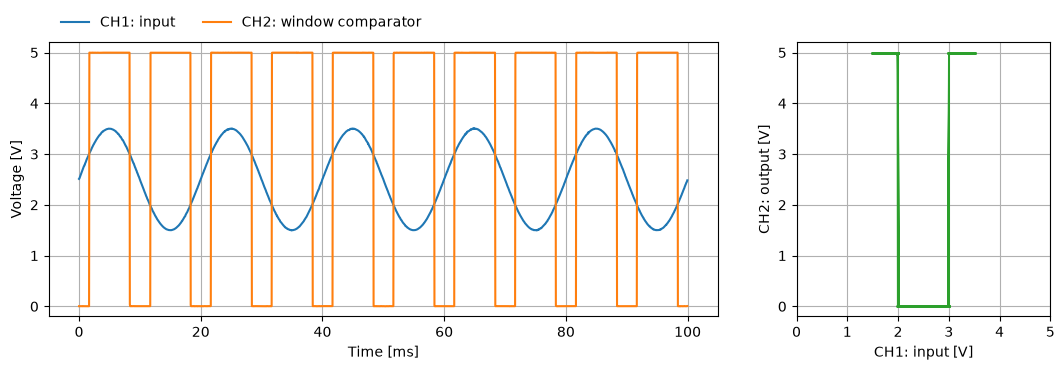

In [3]:
lab.fg.sine(50, 1.0)
lab.mimic.comparator_window(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
high = ch2 > 2.5
print(f"outside the window: {np.mean(high) * 100:.1f} % of the time (theory 66.7 %)")
print(f"pulses: {np.count_nonzero(~high[:-1] & high[1:])} in 0.1 s (5 periods of the input)")
scope_xy(t, ch1, ch2, "window comparator")

入力の 5 周期のあいだに、パルスはおよそ 10 個(山と谷で 1 つずつ)出ます。取り込みの始めと終わりで、パルスが途中で切れることがあります。

## 実験 2:入出力特性

20 Hz、振幅 1.5 V の三角波で、入力を 1.0〜4.0 V までまっすぐに動かして、入出力特性を見ます。窓は 2.0〜3.0 V のままです。窓に入るときと出るときの入力の電圧も調べます。

switched at 3.01, 2.99, 2.00, 2.01, 3.00, 2.99, 2.00, 2.01 V


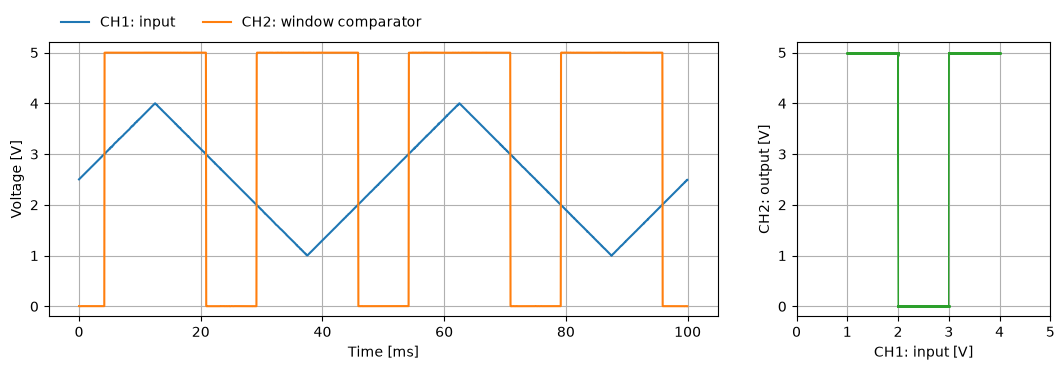

In [4]:
lab.fg.triangle(20, 1.5)
lab.mimic.comparator_window(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
high = ch2 > 2.5
edges = np.flatnonzero(high[:-1] != high[1:]) + 1
print("switched at", ", ".join(f"{v:.2f}" for v in ch1[edges]), "V")
scope_xy(t, ch1, ch2, "window comparator")

入出力特性(右)は、2.0 V と 3.0 V のあいだだけ LOW になる形で、模式図と同じです。ウィンドウ比較器にはヒステリシスがないので、入る向きでも出る向きでも同じ電圧で切り替わります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 窓の幅を変える

正弦波(振幅 1 V)を入れたまま、窓の幅を変えて、窓の外にいる時間を見ます。
<details><summary>ヒント</summary>

`WIDTH` を 1.0 → 0.2 → 1.6 → 2.2 と変えてみましょう(窓は 2.5 V ± 幅の半分)。

- 幅を狭くすると、ほとんどの時間が窓の外になり、HIGH が長くなります。
- 幅を広くすると、山と谷の先だけが窓の外になり、パルスが細くなります。
- 2.2 V は正弦波の振幅(±1 V)より広いので、入力はいつも窓の中で、出力はずっと LOW です。

</details>

outside: 66.8 % (theory 66.7 %)


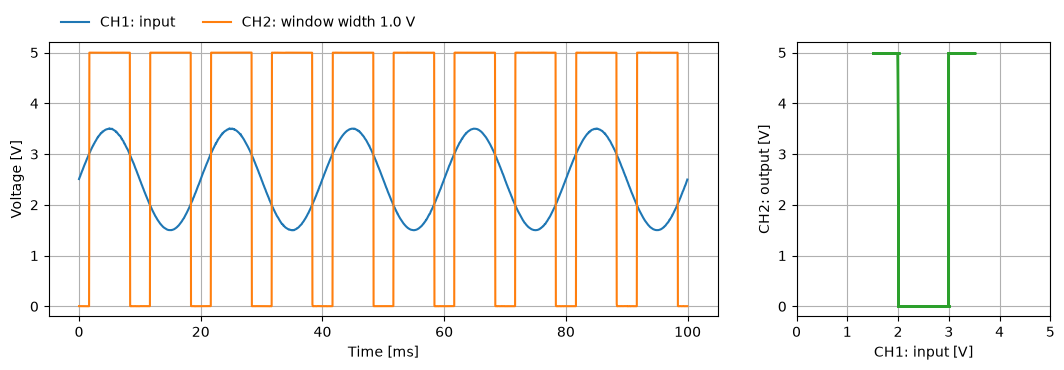

In [5]:
WIDTH = 1.0   # [V]

lab.fg.sine(50, 1.0)
lab.mimic.comparator_window(2.5 + WIDTH / 2, 2.5 - WIDTH / 2)
t, ch1, ch2 = lab.scope.capture(2000)
x = min(WIDTH / 2, 1.0)
print(f"outside: {np.mean(ch2 > 2.5) * 100:.1f} % (theory {(1 - 2 / np.pi * np.arcsin(x)) * 100:.1f} %)")
scope_xy(t, ch1, ch2, f"window width {WIDTH} V")

### 2. 窓をずらす

窓の位置を上にずらします。パルスはどう変わるでしょうか。
<details><summary>ヒント</summary>

`CENTER`(窓の中心)を 2.5 → 2.8 → 3.0 と変えてみましょう(幅は 1 V のまま)。中心を上げると、窓の上(山)のパルスは細くなり、窓の下(谷)のパルスは太くなります。3.0 V では窓が 2.5〜3.5 V なので、山(最大 3.5 V)では窓の外に出られず、谷のパルスだけになります(1 周期に 1 個)。

</details>

pulses: 10 in 0.1 s


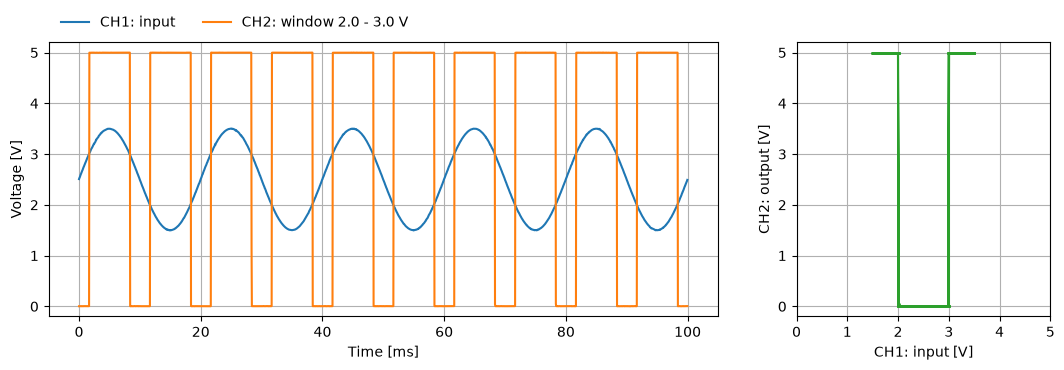

In [6]:
CENTER = 2.5   # [V]

lab.fg.sine(50, 1.0)
lab.mimic.comparator_window(CENTER + 0.5, CENTER - 0.5)
t, ch1, ch2 = lab.scope.capture(2000)
high = ch2 > 2.5
print(f"pulses: {np.count_nonzero(~high[:-1] & high[1:])} in 0.1 s")
scope_xy(t, ch1, ch2, f"window {CENTER - 0.5:.1f} - {CENTER + 0.5:.1f} V")

## まとめ

- ウィンドウ比較器は、入力が窓(下のしきい値〜上のしきい値)の中にあるかを調べる。比較器 2 つとダイオードの OR で作る。
- Mimic は窓の外で HIGH(範囲外の警報)。正弦波を中心に置いた窓に入れると、山と谷で 1 周期に 2 回パルスが出る。
- Mimic では `comparator_window(upper, lower)`。


最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [7]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()